In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from scipy.stats import expon, reciprocal


from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import numpy as np
from scipy.stats import randint, uniform, loguniform
import joblib
import xgboost as xgb

In [2]:
pem = pd.read_csv('../data/pem_electrolyser_dataset.csv', encoding='ISO-8859-1')

In [3]:
pem.head()

,electrolysis_type,Anode_type,Cathode_type,Anode_GDE,Cathode_GDE,electrode_area(cm2),cathode_flow_area(cm2),anode_flow_area(cm2),membrane_type,cathode_catalyst,...,Cell_current_des(A/cm2),power(w),power(W/cm2),water_flow_rate(ml/min),Hydrogen_flow_rate,Temprature_cell(k),Pressuer(atm),Electrode_shape,Flow_type_A (Number),Flow_type_C (Number)
0,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.006964,0.110002,0.018804,6,0.100,293.15,1.0,rectangular,1,1
1,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.014786,0.259501,0.044359,6,0.675,293.15,1.0,rectangular,1,1
2,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.026414,0.509915,0.087165,6,1.100,293.15,1.0,rectangular,1,1
3,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.043238,0.910592,0.155657,6,1.900,293.15,1.0,rectangular,1,1
4,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,5.85,nafion117,MoS2,...,0.064428,1.469932,0.251270,6,3.000,293.15,1.0,rectangular,1,1


In [4]:
# rename columns and set all to lowercase for consistency
pem.columns = pem.columns.str.lower().str.replace(' ', '_').str.replace('(', '').str.replace(')', '')

In [5]:
pem.columns

Index(['electrolysis_type', 'anode_type', 'cathode_type', 'anode_gde',
       'cathode_gde', 'electrode_areacm2', 'cathode_flow_areacm2',
       'anode_flow_areacm2', 'membrane_type', 'cathode_catalyst',
       'anode_catalyst', 'catholyte', 'anolyte', 'cell_design_type',
       'cell_design_number', 'cell_voltage', 'cell_current_desa/cm2', 'powerw',
       'powerw/cm2', 'water_flow_rateml/min', 'hydrogen_flow_rate',
       'temprature_cellk', 'pressueratm', 'electrode_shape',
       'flow_type_a_number', 'flow_type_c_number'],
      dtype='object')

In [6]:
# remove duplicate rows if there are any
pem.drop_duplicates(inplace=True)

In [7]:
pem.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1042 entries, 0 to 1061
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   electrolysis_type      1042 non-null   object 
 1   anode_type             1042 non-null   object 
 2   cathode_type           1042 non-null   object 
 3   anode_gde              1042 non-null   object 
 4   cathode_gde            1042 non-null   object 
 5   electrode_areacm2      1042 non-null   float64
 6   cathode_flow_areacm2   1042 non-null   float64
 7   anode_flow_areacm2     1042 non-null   float64
 8   membrane_type          1042 non-null   object 
 9   cathode_catalyst       1042 non-null   object 
 10  anode_catalyst         1042 non-null   object 
 11  catholyte              1042 non-null   object 
 12  anolyte                1042 non-null   object 
 13  cell_design_type       1042 non-null   object 
 14  cell_design_number     1042 non-null   int64  
 15  cell_volt

In [8]:
# Number of occurences of items in each column
for col in pem.columns:
    col = str(col)
    print(col + ': ', '\n', pem[col].value_counts(), '\n')

electrolysis_type:  
 electrolysis_type
PEM    1042
Name: count, dtype: int64 

anode_type:  
 anode_type
Titanium                                                            519
carbon_plate                                                        334
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Ni_foam                                                               6
Name: count, dtype: int64 

cathode_type:  
 cathode_type
carbon_plate                                                        508
Titanium                                                            351
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Name: count, dtype: int64 

anode_gde:  
 an

In [9]:
print(pem.describe()) # describe dataset

       electrode_areacm2  cathode_flow_areacm2  anode_flow_areacm2  \
count        1042.000000           1042.000000         1042.000000   
mean           39.664875             18.225058           18.688321   
std            30.695271             16.026585           15.699181   
min             9.000000              4.000000            4.000000   
25%            16.000000              5.720000            6.150000   
50%            25.000000              7.920000            9.000000   
75%            64.000000             25.000000           25.000000   
max           100.000000             50.000000           50.000000   

       cell_design_number  cell_voltage  cell_current_desa/cm2       powerw  \
count         1042.000000   1042.000000            1042.000000  1042.000000   
mean             1.970250      3.596026               0.485973    64.177850   
std              2.486868      4.193654               0.483831   153.517598   
min              1.000000      1.380000              

In [10]:
for col in pem.select_dtypes(include='object').columns: #assign category type to categorical features
    pem[col] = pem[col].astype('category')
    
#remove cell_design_type
pem.drop('cell_design_type', axis=1, inplace=True)
pem.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1042 entries, 0 to 1061
Data columns (total 25 columns):
 #   Column                 Non-Null Count  Dtype   
---  ------                 --------------  -----   
 0   electrolysis_type      1042 non-null   category
 1   anode_type             1042 non-null   category
 2   cathode_type           1042 non-null   category
 3   anode_gde              1042 non-null   category
 4   cathode_gde            1042 non-null   category
 5   electrode_areacm2      1042 non-null   float64 
 6   cathode_flow_areacm2   1042 non-null   float64 
 7   anode_flow_areacm2     1042 non-null   float64 
 8   membrane_type          1042 non-null   category
 9   cathode_catalyst       1042 non-null   category
 10  anode_catalyst         1042 non-null   category
 11  catholyte              1042 non-null   category
 12  anolyte                1042 non-null   category
 13  cell_design_number     1042 non-null   int64   
 14  cell_voltage           1042 non-null   float6

In [11]:
# Change flow_type to categorical as well
pem['flow_type_a_number'] = pem['flow_type_a_number'].astype('category')
pem['flow_type_c_number'] = pem['flow_type_c_number'].astype('category')

In [12]:
for columns in pem.columns:
    if pem[columns].dtype == 'category':
        print(f"Value counts for {columns}:\n{pem[columns].value_counts()}\n")

Value counts for electrolysis_type:
electrolysis_type
PEM    1042
Name: count, dtype: int64

Value counts for anode_type:
anode_type
Titanium                                                            519
carbon_plate                                                        334
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Ni_foam                                                               6
Name: count, dtype: int64

Value counts for cathode_type:
cathode_type
carbon_plate                                                        508
Titanium                                                            351
316L_stainless_steel_felt316L_stainless_steel_felt                   77
316L_stainless_steel_felt317L_stainless_steel_felt                   76
silver_coated_3D_printed_components_fabricate_from_polypropylene     30
Name

In [13]:
for col in pem.columns:
    if pem[col].dtypes in ['int64', 'float64']:
        min_value = pem[col].min()
        max_value = pem[col].max()
        print(f"Min, max for {col}:\n min = {min_value}:\n max = {max_value}")
    

Min, max for electrode_areacm2:
 min = 9.0:
 max = 100.0
Min, max for cathode_flow_areacm2:
 min = 4.0:
 max = 50.0
Min, max for anode_flow_areacm2:
 min = 4.0:
 max = 50.0
Min, max for cell_design_number:
 min = 1:
 max = 10
Min, max for cell_voltage:
 min = 1.38:
 max = 19.0
Min, max for cell_current_desa/cm2:
 min = 0.00024083:
 max = 2.0
Min, max for powerw:
 min = 0.00222166:
 max = 1280.0
Min, max for powerw/cm2:
 min = 0.000361245:
 max = 25.6
Min, max for water_flow_rateml/min:
 min = 1:
 max = 1000
Min, max for hydrogen_flow_rate:
 min = 0.0:
 max = 5000.0
Min, max for temprature_cellk:
 min = 293.15:
 max = 403.15
Min, max for pressueratm:
 min = 1.0:
 max = 3.0


#### Plot histogram and boxplots of numerical data

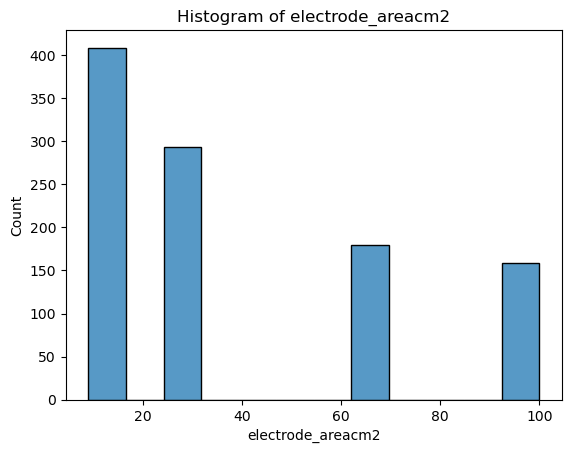

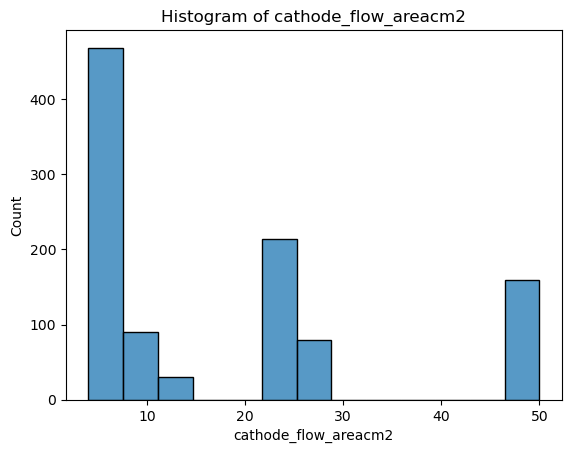

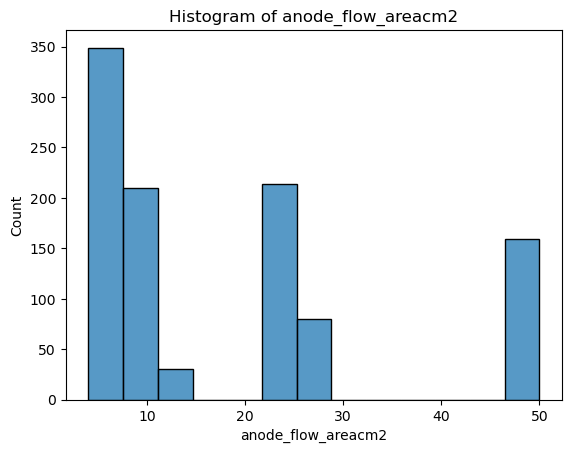

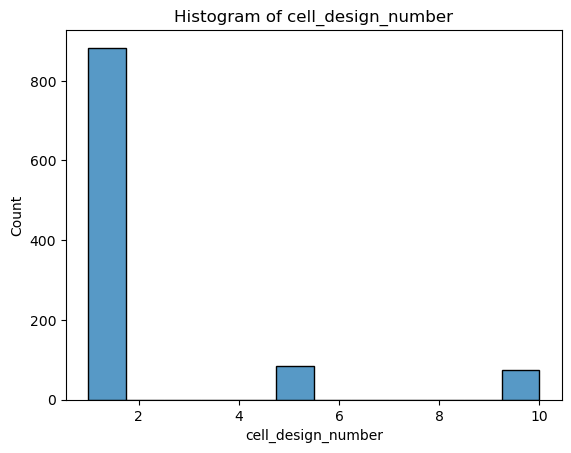

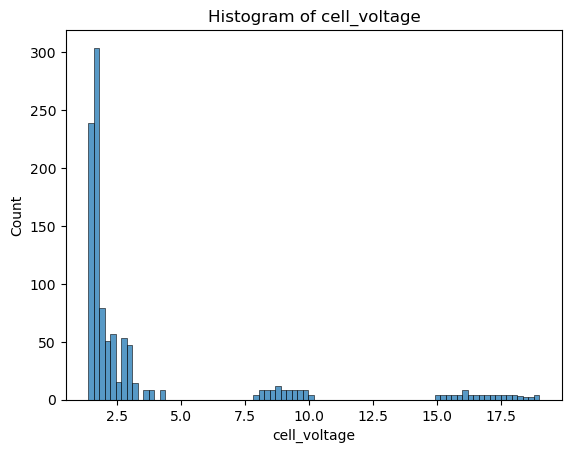

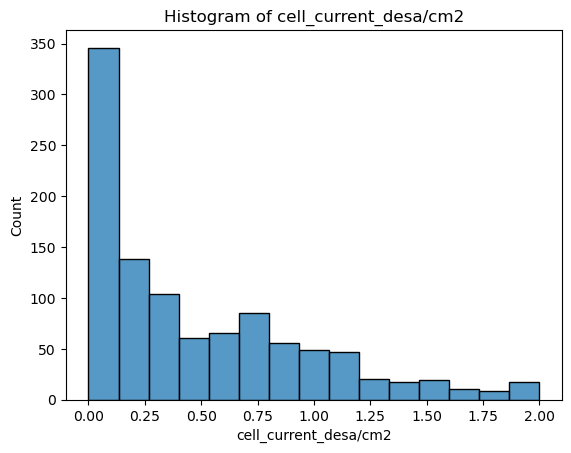

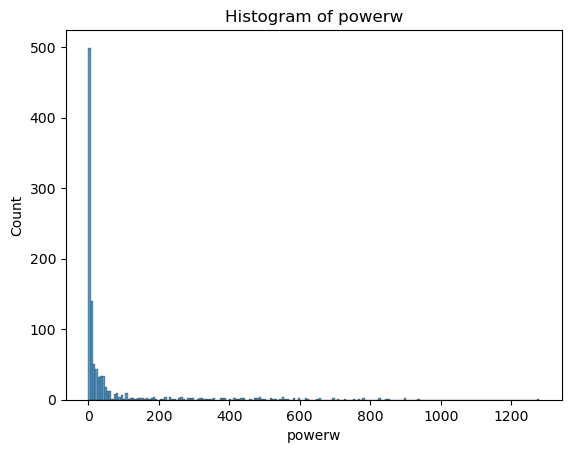

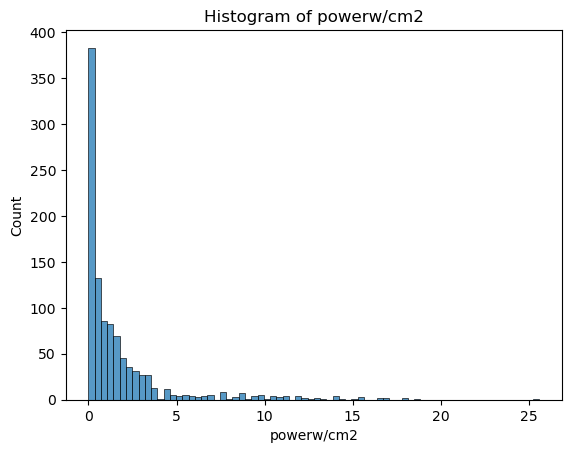

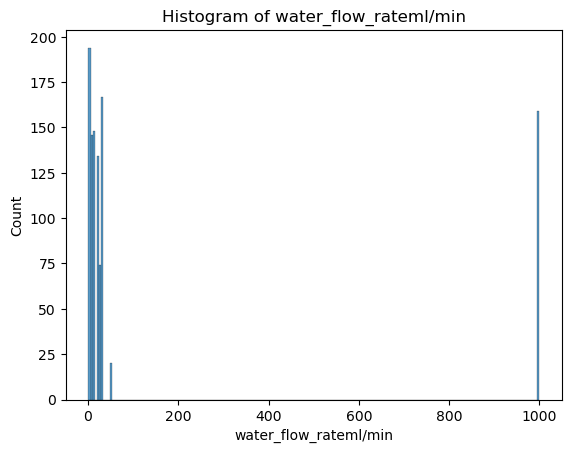

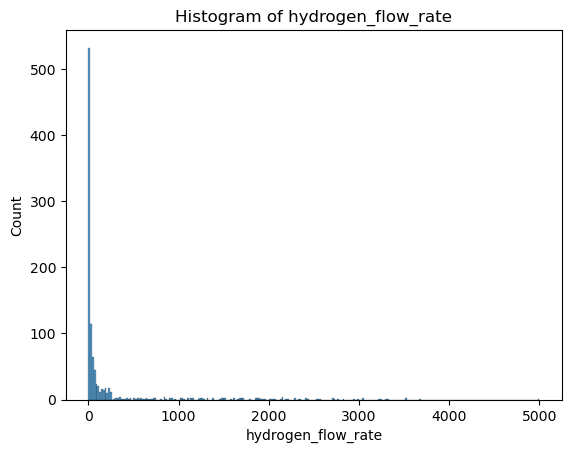

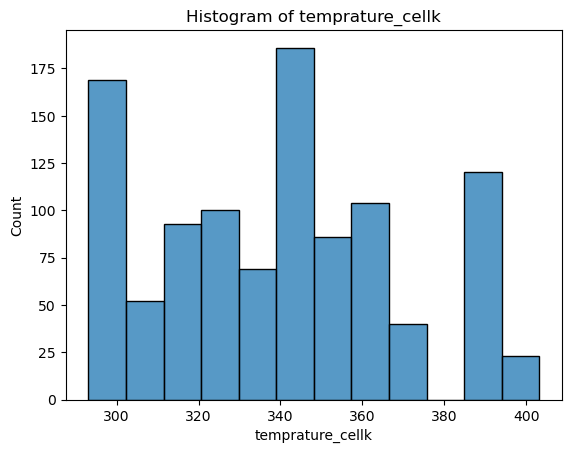

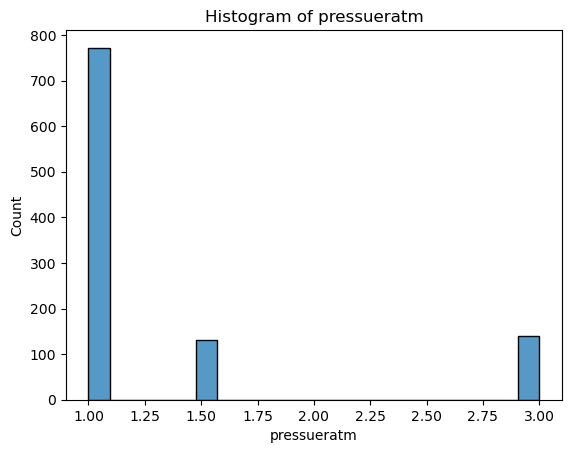

In [14]:
for col in pem.select_dtypes(include=['float64', 'int64']).columns:
    col = str(col)
    sns.histplot(pem[col])
    plt.title('Histogram of ' + col)
    plt.show()

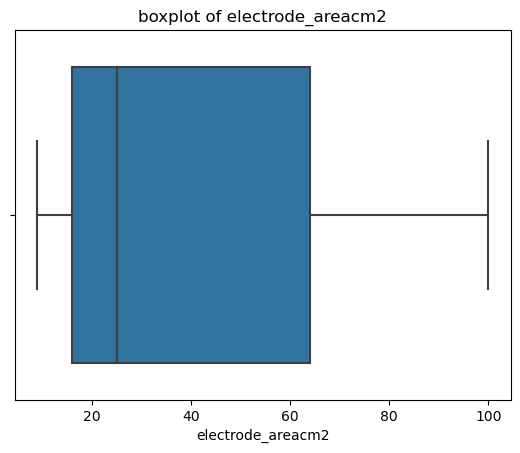

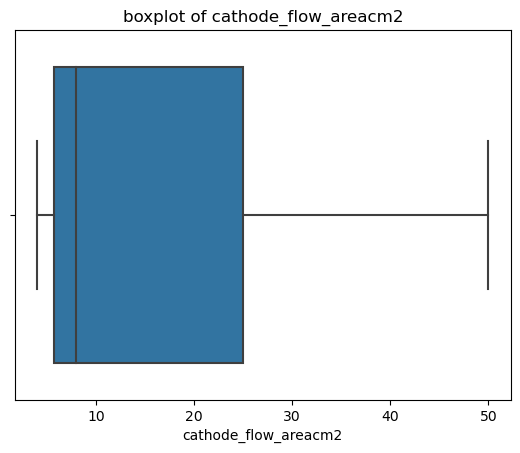

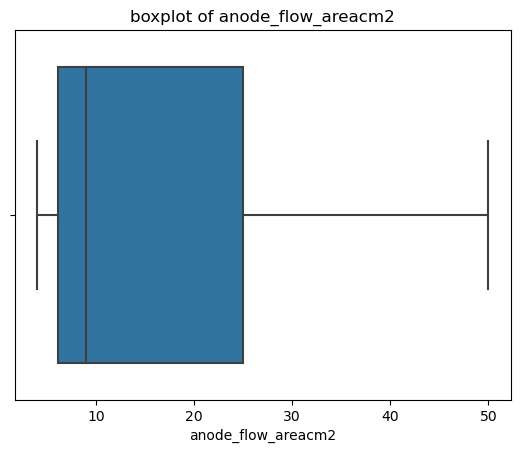

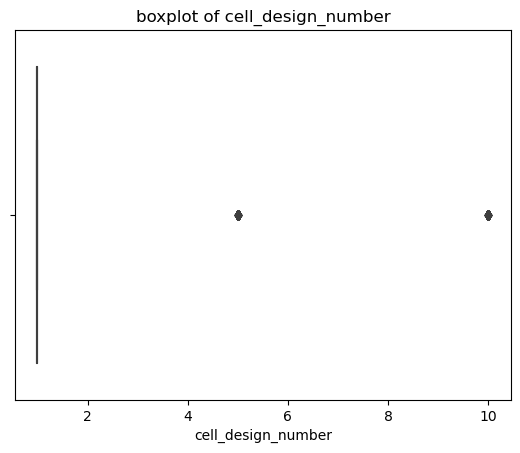

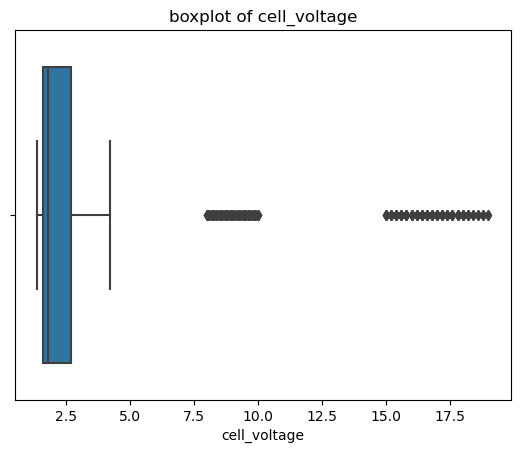

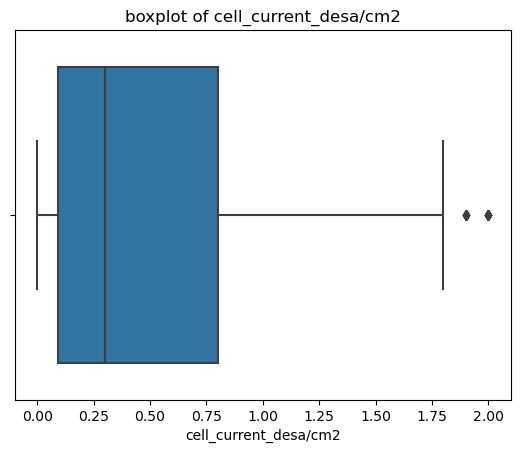

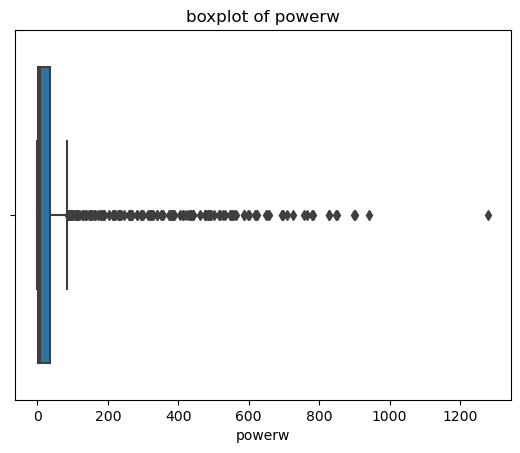

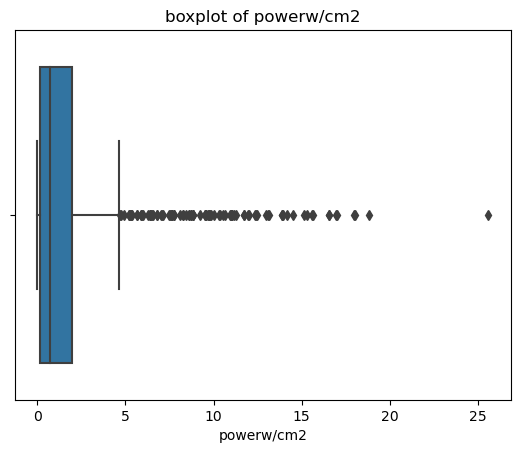

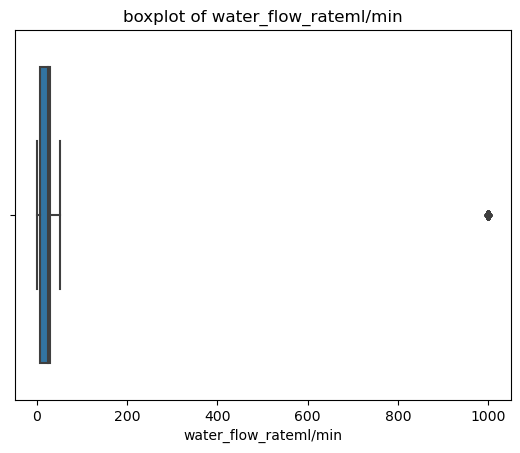

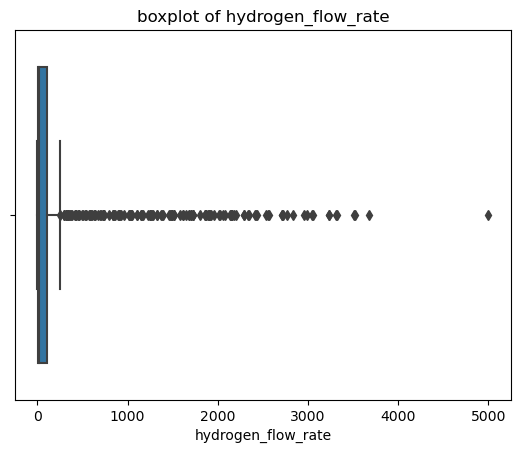

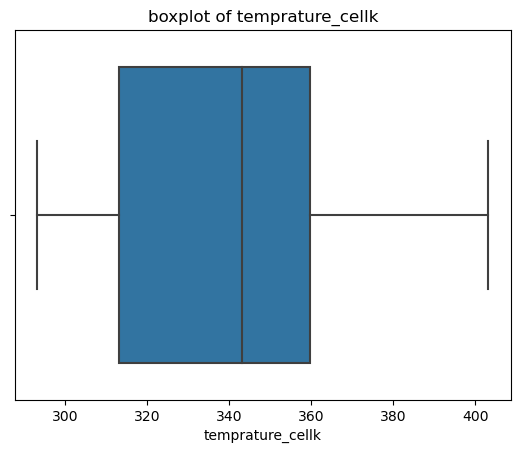

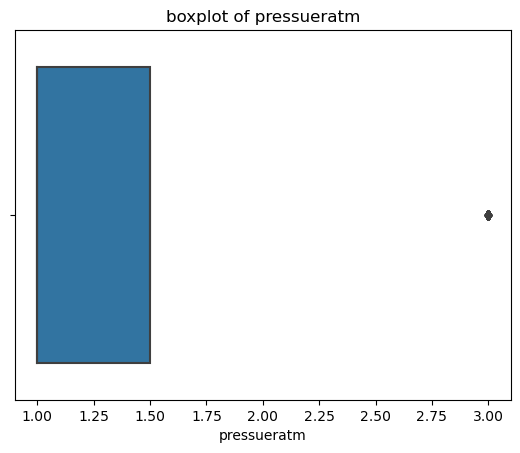

In [15]:
for col in pem.select_dtypes(include=['float64', 'int64']).columns:
    col = str(col)
    sns.boxplot(x=pem[col])
    plt.title('boxplot of ' + col)
    plt.show()

#### Plot correlation matrix

In [16]:
# rename temperature feature
# pem.rename(columns={'temprature_cellk': 'temperature_cell_k'}, inplace=True)

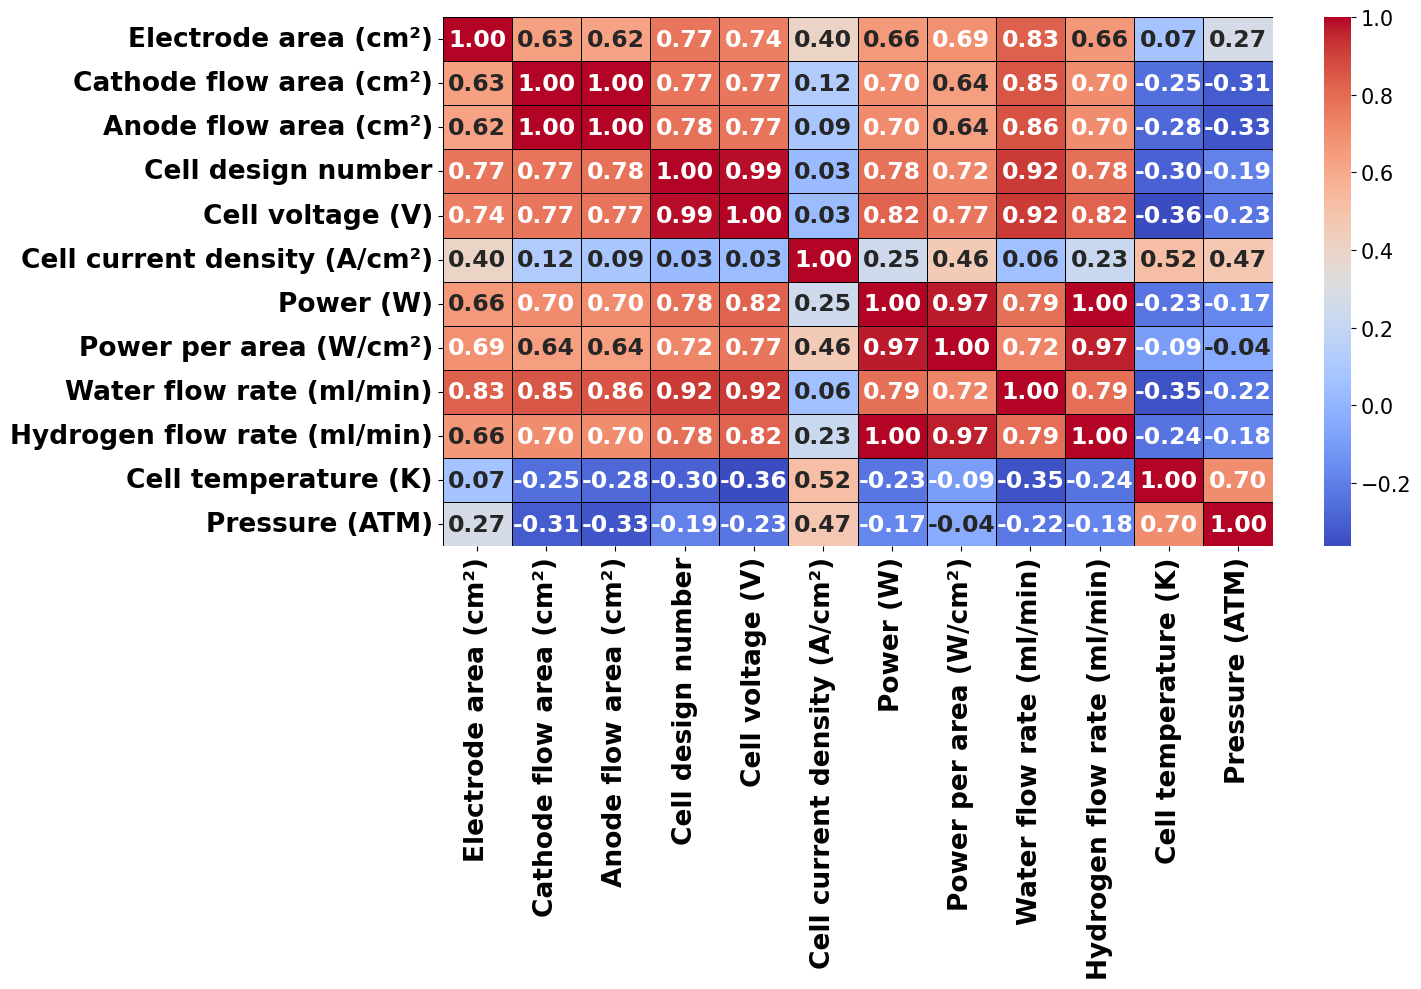

In [17]:

#set pem to new value
pem_1 = pem.copy()
# rename features

pem_1.rename(columns={'temprature_cellk': 'Cell temperature (K)'}, inplace=True)
pem_1.rename(columns={'electrode_areacm2':'Electrode area (cm\u00B2)'}, inplace=True)
pem_1.rename(columns={'cathode_flow_areacm2': 'Cathode flow area (cm\u00B2)'}, inplace=True)
pem_1.rename(columns={'anode_flow_areacm2' : 'Anode flow area (cm\u00B2)'}, inplace=True)
pem_1.rename(columns={'cell_design_number': 'Cell design number'}, inplace=True)
pem_1.rename(columns={'cell_voltage' : 'Cell voltage (V)'}, inplace=True)
pem_1.rename(columns={'cell_current_desa/cm2': 'Cell current density (A/cm\u00B2)'}, inplace=True)
pem_1.rename(columns={'powerw' : 'Power (W)'}, inplace=True)
pem_1.rename(columns={'powerw/cm2' : 'Power per area (W/cm\u00B2)'}, inplace=True)
pem_1.rename(columns={'water_flow_rateml/min': 'Water flow rate (ml/min)'}, inplace=True)
pem_1.rename(columns={'hydrogen_flow_rate': 'Hydrogen flow rate (ml/min)'}, inplace=True)
pem_1.rename(columns={'pressueratm':'Pressure (ATM)'}, inplace=True)

numeric_cols = pem.select_dtypes(include=['int64', 'float64']) # later code is dependent on this
numeric_cols_1 = pem_1.select_dtypes(include=['int64', 'float64'])
correlation_matrix = numeric_cols_1.corr()

plt.figure(figsize=(15, 10))
ax = sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', annot_kws={"size": 17, "weight": "bold"}, linewidths=0.5, linecolor='black' )
# Set x-axis labels
ax.set_xticklabels(ax.get_xmajorticklabels(), fontsize=19, fontweight='bold')

# Set y-axis labels
ax.set_yticklabels(ax.get_ymajorticklabels(), fontsize=19, fontweight='bold')

# Grab the colorbar
colorbar = ax.collections[0].colorbar
# Set colorbar label size and weight
colorbar.ax.yaxis.label.set_size(14)
colorbar.ax.yaxis.label.set_weight('bold')
# You can also set the tick labels size and weight like this
colorbar.ax.tick_params(labelsize=15) # You can adjust the size as necessary

# plt.title('Correlation Matrix')
plt.tight_layout()
plt.savefig('correlation_matrix.png', dpi=1000)
plt.show()


$Power = current\times voltage$ \
Power has very strong correlation with hydrogen flow rate \
Current per square centimeter has 0.46, 0.25 correlation with power per square centimeter $W/cm^2$, power $(W)$ \
Cell_voltage has 0.82, 0.77 correlation with power per square centimeter $W/cm^2$, power $(W)$ 

As power = current * voltage, it may be beneficial to remove power completely as we risk adding contributions from current and voltage twice, may result in inaccurate ML predicitons.

### To avoid multicollinearity, drop following features:
- Water flow rate
- anode flow area = cathode flow area, so one of these can be dropped.

Upon scaling, what are the most influenetial parameters, can use random forest to work this out

In [18]:
pem.columns

Index(['electrolysis_type', 'anode_type', 'cathode_type', 'anode_gde',
       'cathode_gde', 'electrode_areacm2', 'cathode_flow_areacm2',
       'anode_flow_areacm2', 'membrane_type', 'cathode_catalyst',
       'anode_catalyst', 'catholyte', 'anolyte', 'cell_design_number',
       'cell_voltage', 'cell_current_desa/cm2', 'powerw', 'powerw/cm2',
       'water_flow_rateml/min', 'hydrogen_flow_rate', 'temprature_cellk',
       'pressueratm', 'electrode_shape', 'flow_type_a_number',
       'flow_type_c_number'],
      dtype='object')

In [19]:
pem.drop('water_flow_rateml/min', inplace=True, axis=1)
pem.drop('cathode_flow_areacm2', inplace=True, axis=1)
pem.head()

,electrolysis_type,anode_type,cathode_type,anode_gde,cathode_gde,electrode_areacm2,anode_flow_areacm2,membrane_type,cathode_catalyst,anode_catalyst,...,cell_voltage,cell_current_desa/cm2,powerw,powerw/cm2,hydrogen_flow_rate,temprature_cellk,pressueratm,electrode_shape,flow_type_a_number,flow_type_c_number
0,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,2.7,0.006964,0.110002,0.018804,0.100,293.15,1.0,rectangular,1,1
1,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.0,0.014786,0.259501,0.044359,0.675,293.15,1.0,rectangular,1,1
2,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.3,0.026414,0.509915,0.087165,1.100,293.15,1.0,rectangular,1,1
3,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.6,0.043238,0.910592,0.155657,1.900,293.15,1.0,rectangular,1,1
4,PEM,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,9.0,5.85,nafion117,MoS2,MoS2,...,3.9,0.064428,1.469932,0.251270,3.000,293.15,1.0,rectangular,1,1


In [20]:
# X = pem.drop(['hydrogen_flow_rate','electrolysis_type', 'powerw', 'powerw/cm2'] , axis=1)
# # apply dummy coding for the categorical variables
# X = pd.get_dummies(X, columns=X.select_dtypes(include=['category']).columns)
# X.head()

# # seperate target variable
# Y = pem['hydrogen_flow_rate']

# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X)
# rf = RandomForestRegressor()

# #fit the model
# rf.fit(X_scaled, Y)
# #use rf to find most important features
# feature_importance = rf.feature_importances_

In [21]:
# #plot relative importance of the features
# indices = np.argsort(feature_importance)[::-1]

# # To plot the top N most important features
# N = 25
# plt.figure(figsize=(10, 6))
# plt.title("Top N Feature Importances")
# plt.bar(range(N), feature_importance[indices[:N]], align="center")
# plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
# plt.xlim([-1, N])
# plt.show()

From the histograms, we can see that there is a large amount of right skewed data, to combat this we can use a logarithmic transformation. \
This will be performed on the following features:\
- Cell_voltage
- Cell_current_desa/cm2
- Water_flow_rateml/min
- Electrode_area
- cathode_flow_arecm2
- andoe_flow_areacm2
- water_flow_rateml/min
- pressureatm

In [22]:
right_skewed_columns = ['cell_voltage', 'cell_current_desa/cm2', 'electrode_areacm2', 'anode_flow_areacm2', 'pressueratm']
for col in right_skewed_columns:
    # add 1 to all, to avoid log(0) error
    pem[col + '_log'] = np.log(pem[col] + 1)
    
# drop the original columns from the dataframe, so the log columns are the only ones that remain
pem.drop(right_skewed_columns, axis=1, inplace=True)



In [23]:
log_columns = []
for i in right_skewed_columns:
    log_columns.append(i + '_log')

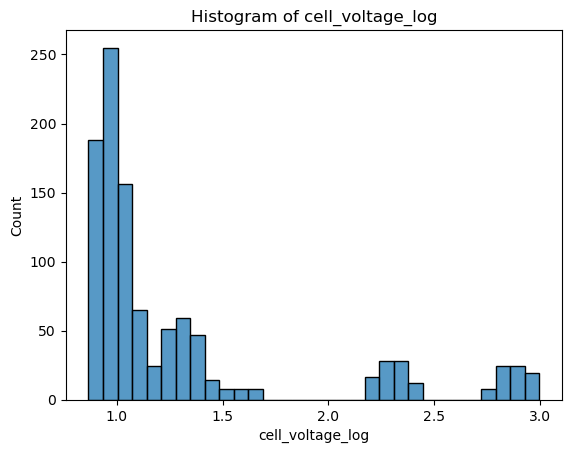

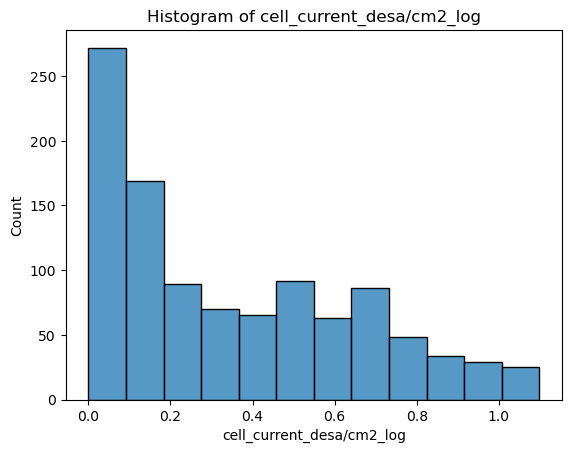

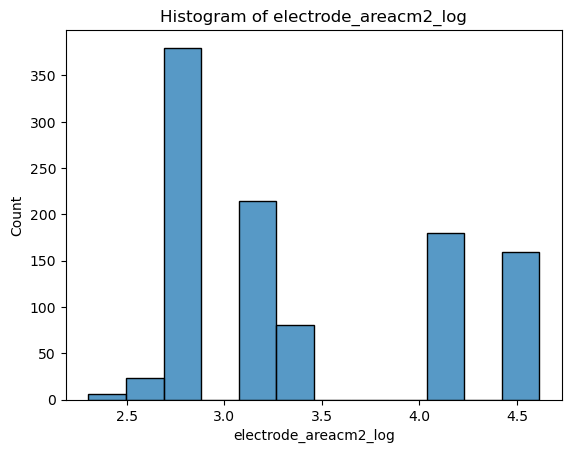

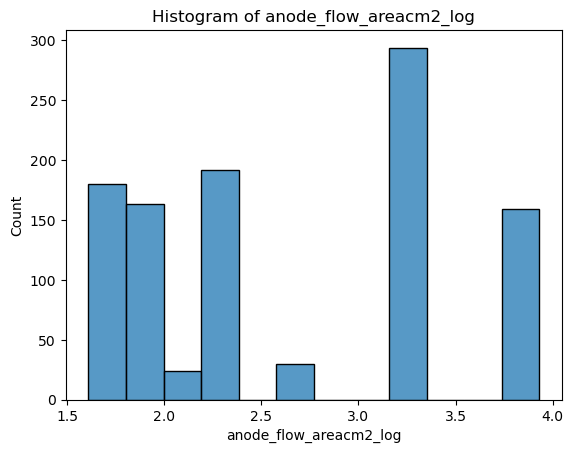

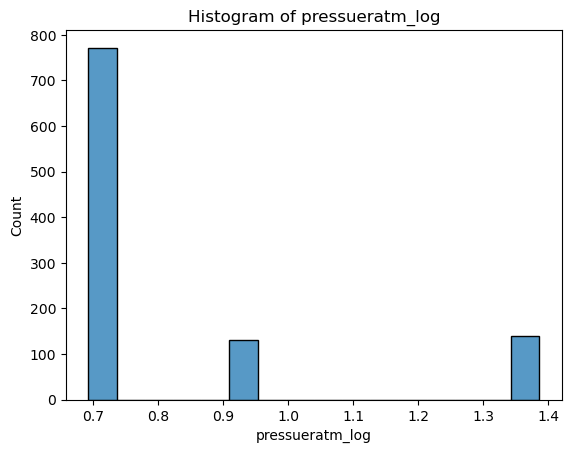

In [24]:
#view histograms and measure skewness
for col in log_columns:
    col = str(col)
    sns.histplot(pem[col])
    plt.title('Histogram of ' + col)
    plt.show()

In [25]:
# remove power and powerw/cm2 from the pem dataframe
pem.drop(['powerw', 'powerw/cm2', 'electrolysis_type'], axis=1, inplace=True)
pem


,anode_type,cathode_type,anode_gde,cathode_gde,membrane_type,cathode_catalyst,anode_catalyst,catholyte,anolyte,cell_design_number,hydrogen_flow_rate,temprature_cellk,electrode_shape,flow_type_a_number,flow_type_c_number,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log
0,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,0.100000,293.15,rectangular,1,1,1.308333,0.006940,2.302585,1.924249,0.693147
1,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,0.675000,293.15,rectangular,1,1,1.386294,0.014678,2.302585,1.924249,0.693147
2,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,1.100000,293.15,rectangular,1,1,1.458615,0.026071,2.302585,1.924249,0.693147
3,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,1.900000,293.15,rectangular,1,1,1.526056,0.042329,2.302585,1.924249,0.693147
4,carbon_plate,carbon_plate,porous_carbon_paper,porous_carbon_paper,nafion117,MoS2,MoS2,choline_0.5M,H2SO4_0.1mol,1,3.000000,293.15,rectangular,1,1,1.589235,0.062438,2.302585,1.924249,0.693147
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1057,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,2718.750000,333.15,round,29,29,2.912351,0.587787,4.615121,3.931826,0.693147
1058,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,2990.625000,333.15,round,29,29,2.923162,0.625938,4.615121,3.931826,0.693147
1059,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,3233.203125,333.15,round,29,29,2.933857,0.657520,4.615121,3.931826,0.693147
1060,Titanium,Titanium,titanium_mesh,porous_titanium,Nafion_110,0.4_mg_Pt/cm2,2_mg_Ir/cm2+2_mg_pt/cm2,DI_Water,DI_Water,10,3515.625000,333.15,round,29,29,2.944439,0.693147,4.615121,3.931826,0.693147


In [26]:
# for log scales :
for col in pem.columns:
    if pem[col].dtypes in ['int64', 'float64']:
        min_value = pem[col].min()
        max_value = pem[col].max()
        print(f"Min, max for {col}:\n min = {min_value}:\n max = {max_value}")

Min, max for cell_design_number:
 min = 1:
 max = 10
Min, max for hydrogen_flow_rate:
 min = 0.0:
 max = 5000.0
Min, max for temprature_cellk:
 min = 293.15:
 max = 403.15
Min, max for cell_voltage_log:
 min = 0.8671004876833833:
 max = 2.995732273553991
Min, max for cell_current_desa/cm2_log:
 min = 0.0002408010051107634:
 max = 1.0986122886681098
Min, max for electrode_areacm2_log:
 min = 2.302585092994046:
 max = 4.61512051684126
Min, max for anode_flow_areacm2_log:
 min = 1.6094379124341003:
 max = 3.9318256327243257
Min, max for pressueratm_log:
 min = 0.6931471805599453:
 max = 1.3862943611198906


In [27]:
X = pem.drop(['hydrogen_flow_rate'] , axis=1) # Assign hydrogen flow rate as target variable


#scale the features
scaler = StandardScaler()
# scaler = joblib.load('scaler.save')

# seperate target variable
Y = pem['hydrogen_flow_rate']
numerical_cols = X.select_dtypes(include=['float64', 'int64']).columns
categorical_cols = X.select_dtypes(include=['category']).columns

#create column transformer, which scales numerical columns, and leaves categorical ones
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(), categorical_cols)
    ])

preprocessor.fit(X)
transformed_feature_names = preprocessor.named_transformers_['num'].get_feature_names_out(numerical_cols)
print(transformed_feature_names)

# fit data
X_transformed = preprocessor.transform(X)
if hasattr(preprocessor.named_transformers_['cat'], 'get_feature_names_out'):
    onehot_columns = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
    transformed_columns = numerical_cols.tolist() + list(onehot_columns)
    X_df = pd.DataFrame(X_transformed.toarray(), columns=transformed_columns)
else:
    X_df = pd.DataFrame(X_transformed, columns=numerical_cols.tolist() + ['category_' + str(i) for i in range(X_transformed.shape[1] - len(numerical_cols))])

# # scale dataset
# scaler.fit(X)
# scaler.transform(X)


print(numeric_cols)
# # apply dummy coding for the categorical variables
# X = pd.get_dummies(X, columns=X.select_dtypes(include=['category']).columns)
# X.head()

# split data into training and test set
X_train_scaled, X_test_scaled, Y_train, Y_test = train_test_split(X_transformed, Y, test_size=0.2, random_state=42)

X_df.head()


X_df.to_csv('X_df.csv')

# #scaler stuff
# scaler = preprocessor.named_transformers_['num']

# means = scaler.mean_
# std_devs = scaler.scale_

# scaling_info = pd.DataFrame({
#     'Column': numerical_cols,
#     'Mean': means,
#     'Standard Deviation': std_devs
# })

# scaling_info.head()

# scaling_info.to_csv('Scaler_mean_mapping.csv')

# X_train_scaled = scaler.transform(X_train)
# X_test_scaled = scaler.transform(X_test)

# means = scaler.mean_
# std_devs = scaler.scale_

# Mapping means and standard deviations to the feature names
# feature_names = X.columns
# mean_std_mapping = pd.DataFrame({
#     'Feature': feature_names,
#     'Mean': means,
#     'Standard Deviation': std_devs
# })

# print(mean_std_mapping)

# print(means)
# print('\n')
# print(std_devs)


# mean_std_mapping.head()

# mean_std_mapping.to_csv('mean_std_mapping.csv')


['cell_design_number' 'temprature_cellk' 'cell_voltage_log'
 'cell_current_desa/cm2_log' 'electrode_areacm2_log'
 'anode_flow_areacm2_log' 'pressueratm_log']
      electrode_areacm2  cathode_flow_areacm2  anode_flow_areacm2  \
0                   9.0                  5.85                5.85   
1                   9.0                  5.85                5.85   
2                   9.0                  5.85                5.85   
3                   9.0                  5.85                5.85   
4                   9.0                  5.85                5.85   
...                 ...                   ...                 ...   
1057              100.0                 50.00               50.00   
1058              100.0                 50.00               50.00   
1059              100.0                 50.00               50.00   
1060              100.0                 50.00               50.00   
1061              100.0                 50.00               50.00   

      cell_de

In [28]:
def performance_metrics(Y_test, y_pred):
    """Returns the performance metrics of a ml model"""
    mae = mean_absolute_error(Y_test, y_pred)
    mse = mean_squared_error(Y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, y_pred)
    print('R2 score:', r2)
    print('MSE:',  mse)
    print('RMSE', rmse)
    print('MAE', mae)

In [29]:
# instantiate random forest
rf = RandomForestRegressor()

#fit random forest model
rf.fit(X_train_scaled, Y_train)
y_pred_rf = rf.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_rf)


#use rf to find most important features
feature_importance_rf = rf.feature_importances_

R2 score: 0.9980150234325021
MSE: 837.2501697088032
RMSE 28.935275525019687
MAE 8.894990414726076


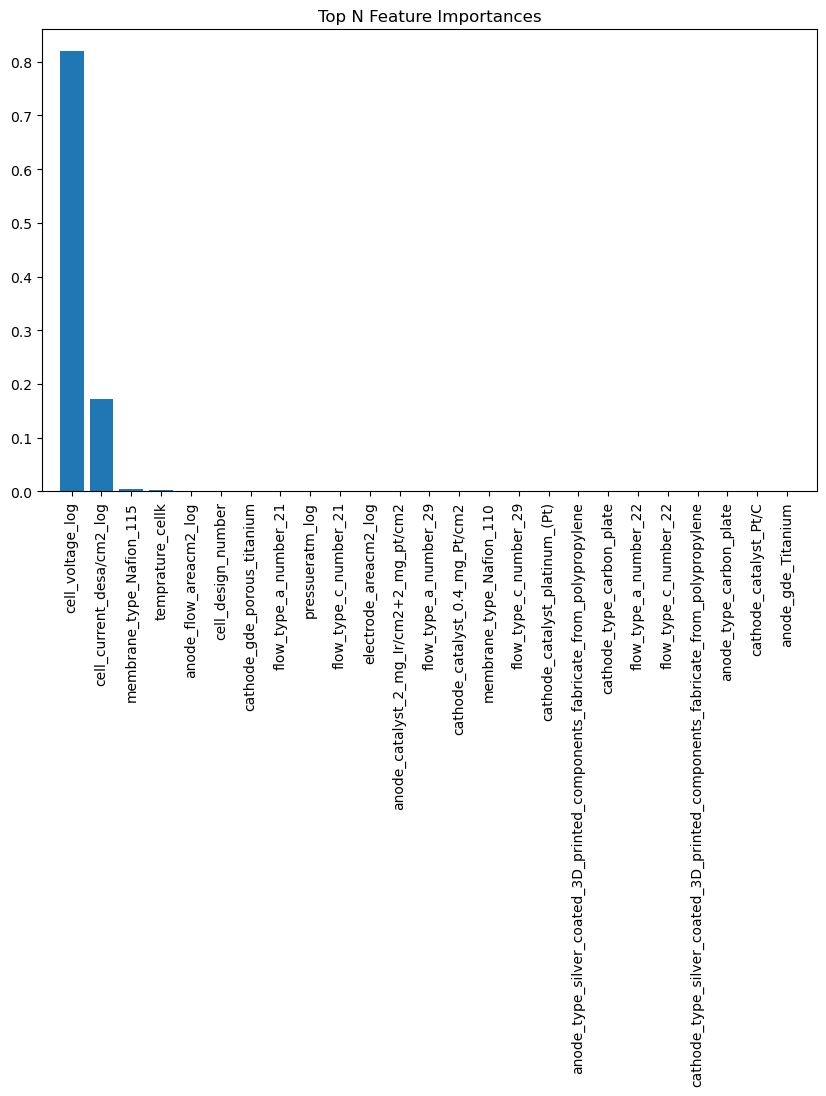

In [30]:
#plot relative importance of the features
indices = np.argsort(feature_importance_rf)[::-1]

# To plot the top N most important features
N = 25
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_rf[indices[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

#### cell_voltage has feature importance of 0.81, which is quite high. To validate this, going to use XGboost to get feature importance as well

In [31]:
# instantiate xgb and fit model
xgb_model = xgb.XGBRegressor()
xgb_model.fit(X_train_scaled, Y_train)

#predicted y values for xgb:
y_pred_xgb = xgb_model.predict(Y_test)
performance_metrics(Y_test, y_pred_xgb)



R2 score: -0.03305450819708389
MSE: 435735.6537446364
RMSE 660.1027599886523
MAE 270.9244380941487


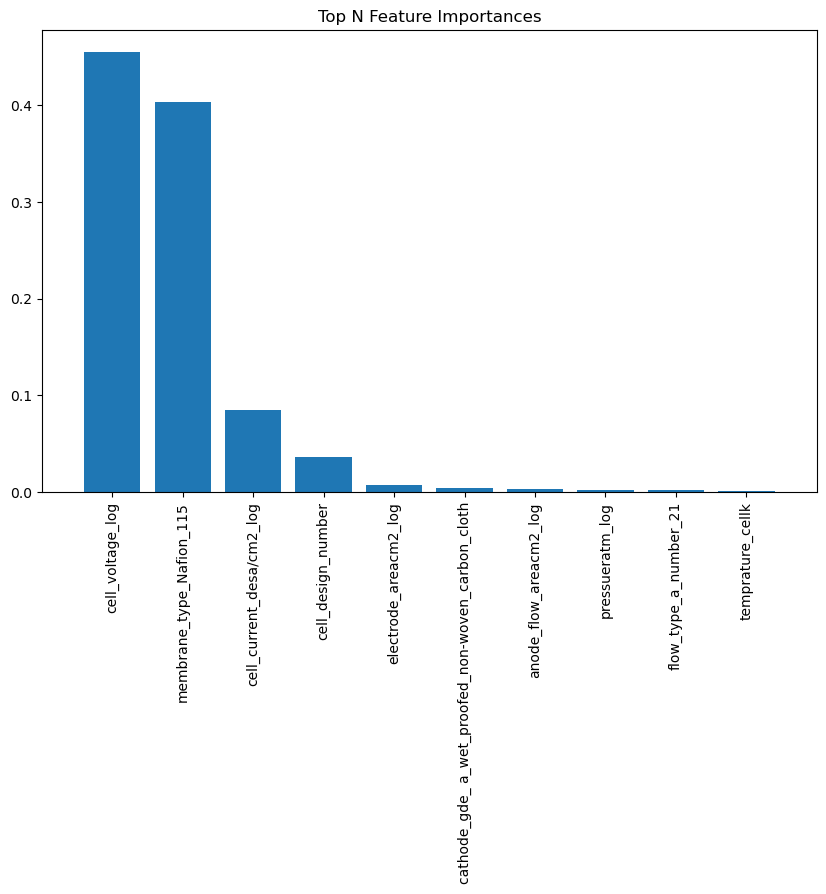

In [32]:
feature_importances_xgb = xgb_model.feature_importances_

#plot relative importance of the features
indices = np.argsort(feature_importances_xgb)[::-1]

# To plot the top N most important features
N = 10
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importances_xgb[indices[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

#### XGB not valid as r2 score is so low, which means model is not accurately predicting
#### so save pem_modified dataset to a csv file

In [33]:

# Instantiate models
linear_model = LinearRegression()
rf_model = RandomForestRegressor()
knn_model = KNeighborsRegressor()
dt_model = DecisionTreeRegressor()
svm_model = SVR()

# Train models
linear_model.fit(X_train_scaled, Y_train)
rf_model.fit(X_train_scaled, Y_train)
knn_model.fit(X_train_scaled, Y_train)
dt_model.fit(X_train_scaled, Y_train)
svm_model.fit(X_train_scaled, Y_train)

SVR()

In [34]:
models = [linear_model, rf_model, knn_model, dt_model, svm_model]
model_names = ['Linear Regression', 'Random Forest', 'KNN', 'Decision Tree', 'SVM']

# evaluate errors
for model, name in zip(models, model_names):
    y_pred = model.predict(X_test_scaled)
    mae = mean_absolute_error(Y_test, y_pred)
    mse = mean_squared_error(Y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, y_pred)
    print(f"{name} - MAE: {mae}, MSE: {mse}, RMSE: {rmse}, R²: {r2}")

Linear Regression - MAE: 186.6993949897971, MSE: 115753.42226928337, RMSE: 340.2255461738336, R²: 0.7255684870244661
Random Forest - MAE: 8.626012661119871, MSE: 748.1120860182302, RMSE: 27.351637720952475, R²: 0.9982263545421262
KNN - MAE: 16.66864779443637, MSE: 3372.7684438434458, RMSE: 58.07554083987032, R²: 0.9920037444352459
Decision Tree - MAE: 13.294848257038277, MSE: 1753.8434598168758, RMSE: 41.87891426263192, R²: 0.995841937933549
SVM - MAE: 209.23022774757266, MSE: 417728.5467372133, RMSE: 646.3192297442598, R²: 0.009637254374421422


#### Random forest and decision tree should be explored further. Tune hyperparameters using randomized search:

In [35]:
# Define the RandomForestRegressor model
rf_model1 = RandomForestRegressor()

# Define the distribution of hyperparameters for RandomizedSearch
param_dist = {
    'n_estimators': randint(100, 500),  # Number of trees in the forest
    'max_features': ['auto', 'sqrt', 'log2'],  # Number of features to consider at every split
    'max_depth': randint(10, 100),  # Maximum number of levels in tree
    'min_samples_split': randint(2, 10),  # Minimum number of samples required to split a node
    'min_samples_leaf': randint(1, 4),  # Minimum number of samples required at each leaf node
    'bootstrap': [True, False]  # Method of selecting samples for training each tree
}

# Set up the random search with cross-validation
random_search = RandomizedSearchCV(rf_model1, param_distributions=param_dist, n_iter=100, cv=5, verbose=2, random_state=42, n_jobs=-1)
random_search.fit(X_train_scaled, Y_train)


Fitting 5 folds for each of 100 candidates, totalling 500 fits


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py:425: FitFailedWarning: 
155 fits failed out of a total of 500.
The score on these train-test partitions for these parameters will be set to nan.
If these failures are not expected, you can try to debug them by setting error_score='raise'.

Below are more details about the failures:
--------------------------------------------------------------------------------
84 fits failed with the following error:
Traceback (most recent call last):
  File "C:\ProgramData\Anaconda3\lib\site-packages\sklearn\model_selection\_validation.py", line 732, in _fit_and_score
    estimator.fit(X_train, y_train, **fit_params)
  File "C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py", line 1144, in wrapper
    estimator._validate_params()
  File "C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py", line 637, in _validate_params
    validate_parameter_constraints(
  File "C:\ProgramData\Anaconda3\lib\site-package

RandomizedSearchCV(cv=5, estimator=RandomForestRegressor(), n_iter=100,
                   n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000021BE187D190>,
                                        'max_features': ['auto', 'sqrt',
                                                         'log2'],
                                        'min_samples_leaf': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000021BE2159C40>,
                                        'min_samples_split': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000021BE21593A0>,
                                        'n_estimators': <scipy.stats._distn_infrastructure.rv_discrete_frozen object at 0x0000021BE18761F0>},
                   random_state=42, verbose=2)

In [36]:
# best_parameters = random_search.best_params_
# print(best_parameters)

In [37]:
# instantiate rf model with the tuned hyperparameters
rf_model_tuned = RandomForestRegressor(n_estimators=322, max_depth=76, max_features='sqrt', min_samples_leaf=1, min_samples_split=3, bootstrap=False)
#fit the model
rf_model_tuned.fit(X_train_scaled, Y_train)

#use rf to find most important features
feature_importance_rf = rf_model_tuned.feature_importances_

joblib.dump(rf_model_tuned, 'rf_tuned.joblib')


['rf_tuned.joblib']

In [38]:
y_pred = rf_model_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred)


R2 score: 0.9934865970832248
MSE: 2747.310868423024
RMSE 52.41479627379109
MAE 14.349719831467587


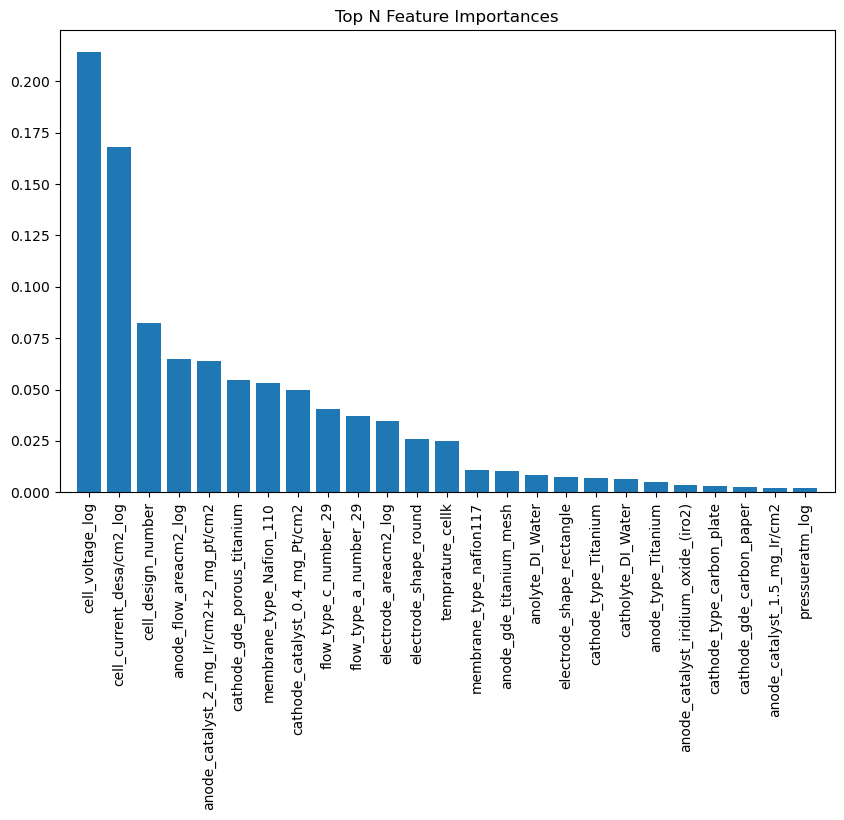

In [39]:
#plot relative importance of the features
indices = np.argsort(feature_importance_rf)[::-1]

# To plot the top N most important features
N = 25
plt.figure(figsize=(10, 6))
plt.title("Top N Feature Importances")
plt.bar(range(N), feature_importance_rf[indices[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

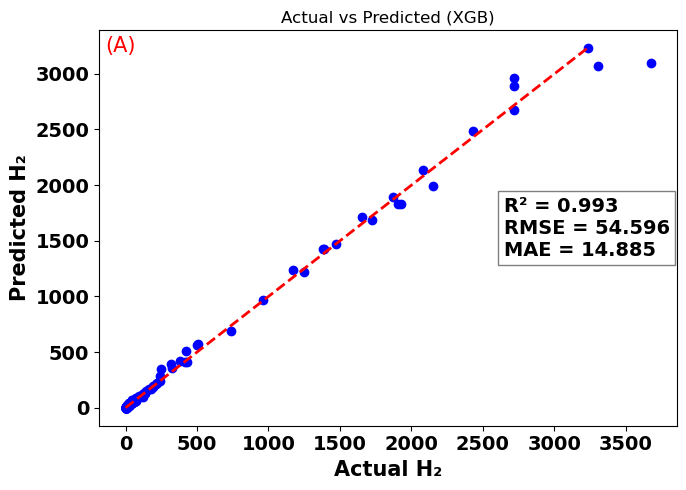

In [50]:
r2 = r2_score(Y_test, y_pred)
rmse = mean_squared_error(Y_test, y_pred, squared=False)
mae = mean_absolute_error(Y_test, y_pred)

# Create the scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(Y_test, y_pred, color='blue')
plt.plot([y_pred.min(), y_pred.max()], [y_pred.min(), y_pred.max()], 'r--', lw=2)
plt.xlabel('Actual H₂', fontweight='bold', fontsize=15)
plt.ylabel('Predicted H₂', fontweight='bold',fontsize=15)
plt.title('Actual vs Predicted (XGB)')

# Annotate the statistics on the plot

plt.text(0.70, 0.5, f'R² = {0.993:.3f}\nRMSE = {54.596:.3f}\nMAE = {14.885:.3f}', fontsize=14, fontweight='bold',
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  # This ensures the position is relative to the axes
         bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.01,0.96, '(A)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
# Make sure to adjust the limits or the layout if the text is cut off
plt.tight_layout()
plt.savefig('XGB_prediction_accuracy_plot.png', dpi=1000)
plt.show()


# DTR

In [41]:
# Define the DecisionTreeRegressor model
dt_model = DecisionTreeRegressor()

# Define the distribution of hyperparameters for RandomizedSearch
param_dist = {
    'max_depth': [None] + list(range(1, 20)),  # Maximum depth of the tree
    'min_samples_split': randint(2, 20),  # Minimum number of samples required to split a node
    'min_samples_leaf': randint(1, 20),  # Minimum number of samples required at each leaf node
    'max_features': ['auto', 'sqrt', 'log2', None]  # Number of features to consider at every split
}

# Set up the random search with cross-validation
random_search_dt = RandomizedSearchCV(dt_model, param_distributions=param_dist, n_iter=100, cv=5, verbose=2, random_state=42, n_jobs=-1)
random_search_dt.fit(X_train, Y_train)

In [42]:
# #print best params for dt model
# best_params_dt = random_search_dt.best_params_
# print(best_params_dt)

In [52]:
# instantiate dt model with tuned hyperparamaters
dt_model_tuned = DecisionTreeRegressor(max_depth=11, max_features='log2', min_samples_leaf=1, min_samples_split=2)

#fit model
dt_model_tuned.fit(X_train_scaled, Y_train)

#get performance metrics
y_pred_dt = dt_model_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_dt)

# use dt to plot feature importance
feature_importance_dt = dt_model_tuned.feature_importances_


R2 score: 0.9892615819746086
MSE: 4529.394684742496
RMSE 67.30077774247854
MAE 25.1109499970876


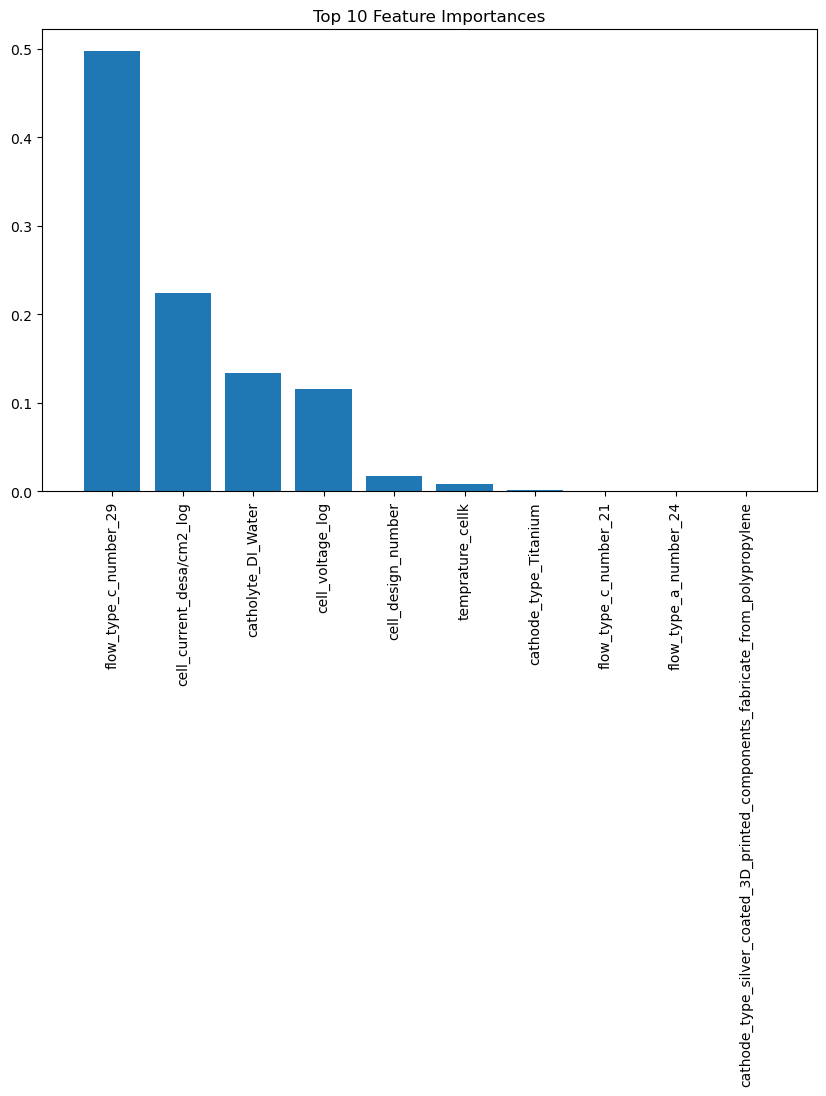

In [53]:
#plot relative importance of the features
indices = np.argsort(feature_importance_dt)[::-1]

# To plot the top N most important features
N = 10
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances")
plt.bar(range(N), feature_importance_dt[indices[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

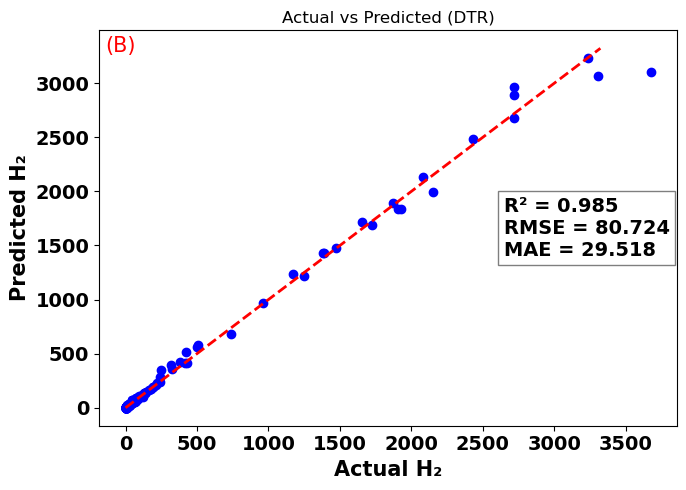

In [55]:
r2 = r2_score(Y_test, y_pred_dt)
rmse = mean_squared_error(Y_test, y_pred_dt, squared=False)
mae = mean_absolute_error(Y_test, y_pred_dt)

# Create the scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(Y_test, y_pred, color='blue')
plt.plot([y_pred_dt.min(), y_pred_dt.max()], [y_pred_dt.min(), y_pred_dt.max()], 'r--', lw=2)
plt.xlabel('Actual H₂', fontweight='bold', fontsize=15)
plt.ylabel('Predicted H₂', fontweight='bold', fontsize=15)
plt.title('Actual vs Predicted (DTR)')

# Annotate the statistics on the plot

plt.text(0.70, 0.5, f'R² = {0.985:.3f}\nRMSE = {80.724:.3f}\nMAE = {29.518:.3f}', fontsize=14, fontweight='bold',
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  # This ensures the position is relative to the axes
         bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.01,0.96, '(B)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
# Make sure to adjust the limits or the layout if the text is cut off
plt.tight_layout()
plt.savefig('DTR_prediction_accuracy_plot.png', dpi=1000)
plt.show()


#### Tune hyperparameters for all machine learning models being considered

# GBM

In [46]:
# # XGB
# xgb_regressor1 = xgb.XGBRegressor()
# params = {
#     'n_estimators': [100, 200, 300, 400, 500],
#     'learning_rate': [0.01, 0.05, 0.1, 0.2, 0.3],
#     'max_depth': [3, 4, 5, 6, 7, 8],
#     'colsample_bytree': [0.3, 0.5, 0.7],
#     'min_child_weight': [1, 3, 5],
#     'subsample': [0.5, 0.7, 0.9]
# }
# random_search = RandomizedSearchCV(xgb_regressor1, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)
# random_search.fit(X_train, Y_train)
# best_model = random_search.best_estimator_
# print("Best hyperparameters:", random_search.best_params_)


In [57]:
#instantiate xgb tuned
xgb_regressor_tuned = xgb.XGBRegressor(subsample=0.9, n_estimators=400, min_child_weight=1, max_depth=3, learning_rate=0.05, colsample_bytree=0.7)
#fit model
xgb_regressor_tuned.fit(X_train_scaled ,Y_train)
#get performance metrics
y_pred_xgb = xgb_regressor_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_xgb)

# use dt to plot feature importance
feature_importance_xgb = xgb_regressor_tuned.feature_importances_


R2 score: 0.997567806778836
MSE: 1025.8832373779996
RMSE 32.029412067317125
MAE 11.668351246250982


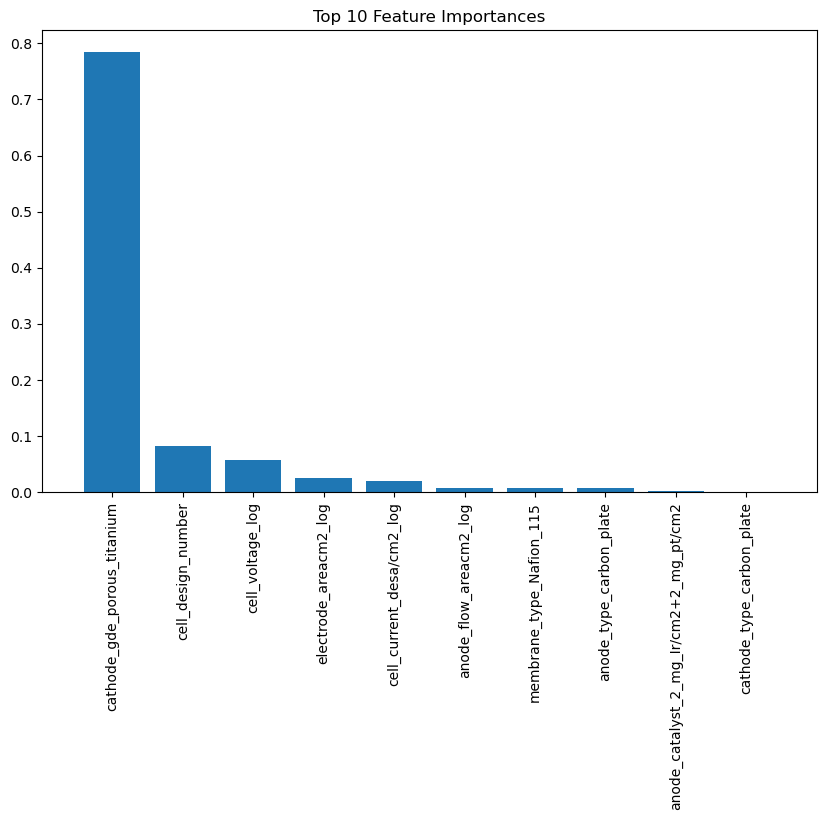

In [48]:
#plot relative importance of the features
indices = np.argsort(feature_importance_xgb)[::-1]

# To plot the top N most important features
N = 10
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances")
plt.bar(range(N), feature_importance_xgb[indices[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

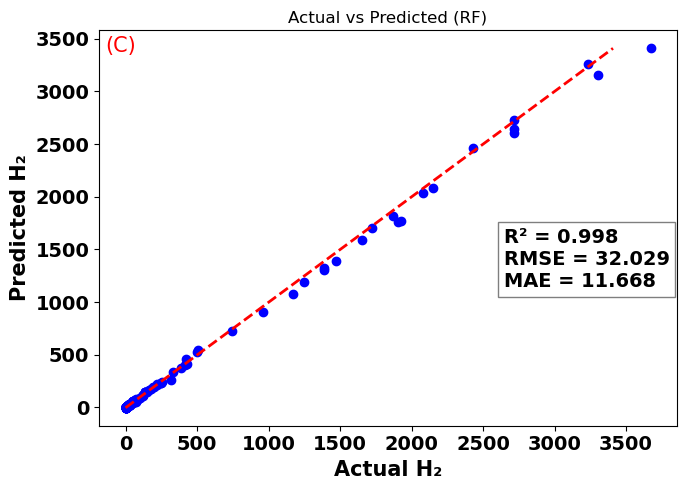

In [59]:
r2 = r2_score(Y_test, y_pred_xgb)
rmse = mean_squared_error(Y_test, y_pred_xgb, squared=False)
mae = mean_absolute_error(Y_test, y_pred_xgb)

# Create the scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(Y_test, y_pred_xgb, color='blue')
plt.plot([y_pred_xgb.min(), y_pred_xgb.max()], [y_pred_xgb.min(), y_pred_xgb.max()], 'r--', lw=2)
plt.xlabel('Actual H₂', fontweight='bold', fontsize=15)
plt.ylabel('Predicted H₂', fontweight='bold', fontsize=15)
plt.title('Actual vs Predicted (RF)')

# Annotate the statistics on the plot

plt.text(0.70, 0.5, f'R² = {0.998:.3f}\nRMSE = {32.029:.3f}\nMAE = {11.668:.3f}', fontsize=14, fontweight='bold',
         verticalalignment='top', horizontalalignment='left',
         transform=plt.gca().transAxes,  # This ensures the position is relative to the axes
         bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.01,0.96, '(C)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
# Make sure to adjust the limits or the layout if the text is cut off
plt.tight_layout()
plt.savefig('RF_prediction_accuracy_plot.png', dpi=1000)
plt.show()


# SVM

In [50]:
# Define your SVR model
# svm_regressor1 = SVR()

# # Set up hyperparameter space
# params = {
#     'C': reciprocal(0.001, 100),  # Regularization parameter
#     'kernel': ['linear', 'poly', 'rbf', 'sigmoid'],  # Type of the kernel
#     'degree': [2, 3, 4, 5],  # Degree of the polynomial kernel
#     'gamma': expon(scale=1.0),  # Kernel coefficient
#     'coef0': [0.0, 0.5, 1.0],  # Independent term in kernel function
#     'shrinking': [True, False],  # Shrinking heuristic
#     'tol': [1e-3, 1e-4, 1e-5],  # Tolerance for stopping criterion
#     'epsilon': [0.01, 0.1, 0.2, 0.5]  # Epsilon in the epsilon-SVR model
# }

# # Configure Randomized Search
# random_search_svm = RandomizedSearchCV(svm_regressor1, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)

# # Fit the Randomized Search Model
# random_search_svm.fit(X_train, Y_train)

# # Best model and hyperparameters
# best_model_svm = random_search_svm.best_estimator_
# print("Best hyperparameters for SVM Regression:", random_search_svm.best_params_)

In [51]:
# svm_regressor_tuned = SVR()
# #fit model
# svm_regressor_tuned.fit(X_train, Y_train)
# #get performance metrics
# y_pred_SVR = svm_regressor_tuned.predict(X_test_scaled)
# performance_metrics(Y_test, y_pred_SVR)

# #feature importance
# feature_importance_SVR = svm_regressor_tuned.feature_importances

In [52]:
# #plot relative importance of the features
# indices = np.argsort(feature_importance_xgb)[::-1]

# # To plot the top N most important features
# N = 25
# plt.figure(figsize=(10, 6))
# plt.title("Top N Feature Importances")
# plt.bar(range(N), feature_importance_xgb[indices[:N]], align="center")
# plt.xticks(range(N), X.columns[indices[:N]], rotation=90)
# plt.xlim([-1, N])
# plt.show()

# KNN regressor

In [53]:
# #instantiate model
# knn_regressor = KNeighborsRegressor()
# # Set up extended hyperparameter space
# params = {
#     'n_neighbors': np.arange(1, 31),  # Number of neighbors to use
#     'weights': ['uniform', 'distance'],  # Weight function used in prediction
#     'algorithm': ['ball_tree', 'kd_tree', 'brute', 'auto'],  # Algorithm used to compute the nearest neighbors
#     'leaf_size': np.arange(1, 50),  # Leaf size passed to BallTree or KDTree
#     'p': [1, 2],  # Power parameter for the Minkowski metric
#     'metric': ['euclidean', 'manhattan', 'chebyshev', 'minkowski']  # Distance metric to use
# }

# # Configure Randomized Search
# random_search_knn = RandomizedSearchCV(knn_regressor, param_distributions=params, n_iter=100, scoring='neg_mean_squared_error', n_jobs=-1, cv=5, verbose=3, random_state=42)

# # Assuming X_train, y_train are defined
# # Fit the Randomized Search Model
# random_search_knn.fit(X_train, Y_train)

# # Best model and hyperparameters
# best_model_knn = random_search_knn.best_estimator_
# print("Best hyperparameters for KNN Regression:", random_search_knn.best_params_)


In [60]:
# instantiate knn regressor tuned
knn_regressor_tuned = KNeighborsRegressor(weights='distance', p=1, n_neighbors=2, metric='manhattan', leaf_size=38, algorithm='brute')
#fit model
knn_regressor_tuned.fit(X_train_scaled, Y_train)
#get performance metrics
y_pred_knn = knn_regressor_tuned.predict(X_test_scaled)
performance_metrics(Y_test, y_pred_knn)



R2 score: 0.995358246036697
MSE: 1957.8615471621688
RMSE 44.24772928820381
MAE 9.418320428206028


In [55]:
# for KNN can use permutation feature importance to get relative importances
result = permutation_importance(knn_regressor_tuned, X_test_scaled.toarray(), Y_test, n_repeats=10, random_state=42, n_jobs=-1)





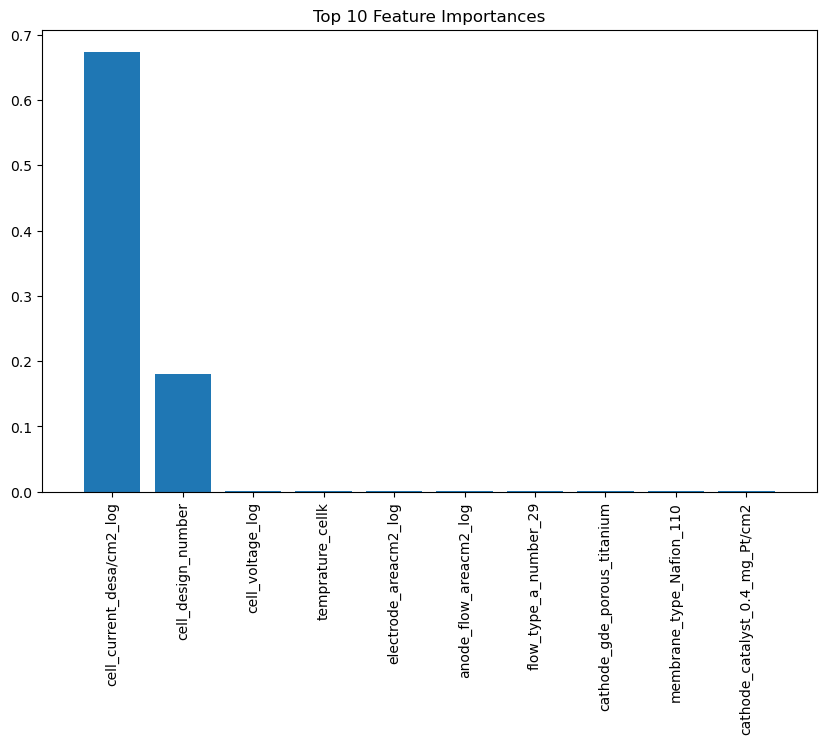

In [56]:
indices_knn = result.importances_mean.argsort()[::-1]


# To plot the top N most important features


N = 10
plt.figure(figsize=(10, 6))
plt.title("Top 10 Feature Importances")
plt.bar(range(N), result.importances_mean[indices_knn[:N]], align="center")
plt.xticks(range(N), X_df.columns[indices_knn[:N]], rotation=90)
plt.xlim([-1, N])
plt.show()

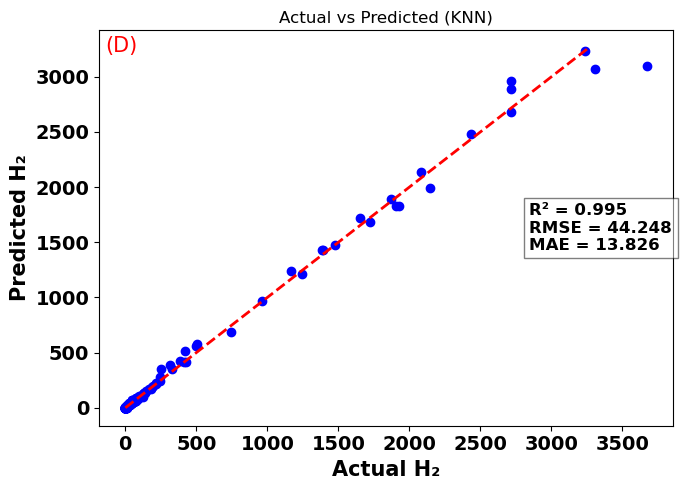

In [64]:
r2 = r2_score(Y_test, y_pred_knn)
rmse = mean_squared_error(Y_test, y_pred_knn, squared=False)
mae = mean_absolute_error(Y_test, y_pred_knn)

# Create the scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(Y_test, y_pred, color='blue')
plt.plot([y_pred_knn.min(), y_pred_knn.max()], [y_pred_knn.min(), y_pred_knn.max()], 'r--', lw=2)
plt.xlabel('Actual H₂', fontweight='bold', fontsize=15)
plt.ylabel('Predicted H₂', fontweight='bold', fontsize=15)
plt.title('Actual vs Predicted (KNN)')

# Annotate the statistics on the plot

plt.text(0.75, 0.5, f'R² = {0.995:.3f}\nRMSE = {44.248:.3f}\nMAE = {13.826:.3f}', fontsize=12, fontweight='bold',
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  # This ensures the position is relative to the axes
         bbox=dict(facecolor='white', alpha=0.5))
plt.text(0.01,0.96, '(D)', fontsize=15, color='red', 
         verticalalignment='center', horizontalalignment='left',
         transform=plt.gca().transAxes,  
         )

plt.xticks(fontsize=14, fontweight='bold')
plt.yticks(fontsize=14, fontweight='bold')
# Make sure to adjust the limits or the layout if the text is cut off
plt.tight_layout()
plt.savefig('KNN_prediction_accuracy_plot.png', dpi=1000)
plt.show()


### Hydrogen scale up sim

In [62]:
#check the optimal parameters
row = X.iloc[1:2]

dummy_df = X_df.select_dtypes(include='bool')
dummy_list = dummy_df.columns.tolist()

print(dummy_list)

for dummy in dummy_list:
    row[dummy] = False

#set up optimal configuration 
# set up the optimal configuration
row['anode_type_Titanium'] = True
row['cathode_type_Titanium'] = True
row['anode_gde_titanium_mesh'] = True
row['cathode_gde_porous_titanium'] = True
row['membrane_type_Nafion_110'] = True
row['cathode_catalyst_0.4_mg_Pt/cm2'] = True
row['anode_catalyst_2_mg_Ir/cm2+2_mg_pt/cm2'] = True
row['catholyte_DI_Water'] = True
row['anolyte_DI_Water'] = True
row['electrode_shape_round'] = True
row['flow_type_a_number_29'] = True
row['flow_type_c_number_29'] = True


row.head()

[]


C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\2188665248.py:15: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['anode_type_Titanium'] = True
C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\2188665248.py:16: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['cathode_type_Titanium'] = True
C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\2188665248.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instea

,cell_design_number,temprature_cellk,cell_voltage_log,cell_current_desa/cm2_log,electrode_areacm2_log,anode_flow_areacm2_log,pressueratm_log,anode_type_316L_stainless_steel_felt316L_stainless_steel_felt,anode_type_316L_stainless_steel_felt317L_stainless_steel_felt,anode_type_Ni_foam,...,flow_type_c_number_20,flow_type_c_number_21,flow_type_c_number_22,flow_type_c_number_23,flow_type_c_number_24,flow_type_c_number_25,flow_type_c_number_26,flow_type_c_number_27,flow_type_c_number_28,flow_type_c_number_29
1,-0.390337,-1.415823,0.152154,-1.121644,-1.675374,-0.910349,-0.510589,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,True


In [63]:
# function for scaling the data

mappings = pd.read_csv('Scaler_mean_mapping.csv')

def scaler_func(x, feature):
    feature_row = mappings[mappings['Column'] == feature]
    if not feature_row.empty:
        mean = feature_row['Mean'].values[0]
        std_dev = feature_row['Standard Deviation'].values[0]
    # scale data
        scaled_data = (x - mean) / std_dev
        return scaled_data
    else:
        raise ValueError(f"Feature '{feature}' not found in scaler mappings.")


row.head()

def scaler_func_log(x, feature):
    x = np.log(x + 1)
    
    feature_row = mappings[mappings['Column'] == feature]
    if not feature_row.empty:
        mean = feature_row['Mean'].values[0]
        std_dev = feature_row['Standard Deviation'].values[0]
    # scale data
        scaled_data = (x - mean) / std_dev
        return scaled_data
    else:
        raise ValueError(f"Feature '{feature}' not found in scaler mappings.")
    

In [65]:
row['cell_design_number'] = scaler_func(10, 'cell_design_number')
row['temprature_cellk'] = scaler_func(337.03, 'temprature_cellk')
row['cell_current_desa/cm2_log'] = scaler_func_log(2, 'cell_current_desa/cm2_log')
row['electrode_areacm2_log'] = scaler_func_log(80.86, 'electrode_areacm2_log')
row['anode_flow_areacm2_log'] = scaler_func_log(50, 'anode_flow_areacm2_log')
row['pressueratm_log'] = scaler_func_log(1, 'pressueratm_log')
row['cell_voltage_log'] = 2.9957319999999994

C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\3002546807.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['cell_design_number'] = scaler_func(10, 'cell_design_number')
C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\3002546807.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  row['temprature_cellk'] = scaler_func(337.03, 'temprature_cellk')
C:\Users\hasee\AppData\Local\Temp\ipykernel_43908\3002546807.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFr

In [66]:
prediction = rf_model_tuned.predict(row)
print(prediction)

[4152.73299765]


C:\ProgramData\Anaconda3\lib\site-packages\sklearn\base.py:457: UserWarning: X has feature names, but RandomForestRegressor was fitted without feature names
  warnings.warn(
